# Demonstration of MSI-IIE usage

This notebook uses a MSI dataset of Alzheimer's disease (AD) and wild type (WT) mouse brains to illustrate the usage of MSI-IIE. We thank the authors of the original paper of the dataset again:\
Trinklein, T.J., Rubakhin, S.S., Okyem, S. et al. Multimodal mass spectrometry imaging for plaque- and region-specific neurolipidomics in Alzheimer’s disease mouse models. Nat Commun 16, 10969 (2025). https://doi.org/10.1038/s41467-025-65956-w


In [2]:
# Visit source code
import sys
sys.path.append(r'E:\yangjun\msi\MSI_IIE')

In [3]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({
    "font.family": "Arial",
    "font.size": 10,
    "axes.labelsize": 10,
    "axes.titlesize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9
})

In [4]:
import image_preprocessing
import train_model
import ion_images
import embedding_models
import ion_clustering

D:\Programs\Anaconda\envs\yj_msi\Lib\site-packages\h5py\__init__.py:36: UserWarning: h5py is running against HDF5 1.14.6 when it was built against 1.14.5, this may cause problems
  _warn(("h5py is running against HDF5 {0} when it was built against {1}, "


In [5]:
import pickle
from image_preprocessing import display_mean_spectra_from_inputs, display_ion_image_from_inputs, save_ion_image, pre_alignment, input_normalization, get_input_size, resize_images
from train_model import train_embedding, plot_loss_curve, train_embedding_pairs, get_training_test_data, train_embedding_pairs_test_pairs
from embedding_models import MultiscaleEmbedding, MultiscaleEmbedding_p

## 1. Get ion images

The first step is to get all the ion images from the dataset. By traversing all the spectra in each MSI data, abundant ion images can be constructed. In the `get_samples_ion_images` function, `blank_pixels_percent` parameter is used to filter the ion images with plently of blank.

In [5]:
sample_path_list = [
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal6_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal7_s2_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section4_jan25_animal8_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section1_jan25_animal5_5xfad_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section4_jan25_animal9_s2_5xfad_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal10_s2_5xfad_neg.imzML'
    ]

sample_id_list = ['wt-1', 'wt-2', 'wt-3', 'ad-1', 'ad-2', 'ad-3']
output_dir = r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\ion_images'
noise_threshold_list = [1e3, 1e3, 1e3, 1e3, 1e3, 1e3]

In [7]:
ion_images.get_samples_ion_images(sample_path_list=sample_path_list,
                           sample_id_list=sample_id_list,
                           ppm_torelance=10,
                           noise_threshold=noise_threshold_list,
                           blank_pixels_percent=0.5,
                           output_directory=output_dir)

Obtaining ion images from wt-1...


Processing coordinates: 100%|████████████████████████████████████████████████████| 22358/22358 [40:28<00:00,  9.21it/s]


(194, 149) (2509,) (2509, 194, 149)
Obtaining ion images from wt-2...


Processing coordinates: 100%|████████████████████████████████████████████████████| 21178/21178 [41:55<00:00,  8.42it/s]


(197, 153) (2559,) (2559, 197, 153)
Obtaining ion images from ad-2...


Processing coordinates:  63%|████████████████████████████████▉                   | 13608/21522 [26:04<16:27,  8.02it/s]

(213, 152) (2277,) (2277, 213, 152)


Now the detected ion images are saved in a file `input_data.pkl` in the specified output folder.

## 2. Load ion image data

This step loads the detected ion images in to memory. The ion images were contained in a list of images from all the files. Each element in the list is also a list `[sample_id, msi_mask, mz_array, intensity_array]`. `msi_mask` is a bool array of the image indicating the true tissue region. `mz_array` is an array of the m/z values of the ion images. `intensity_array` is the intensitity matrix of all ioin images with three axises. The first represents the m/z axis, and the second and third represent the image width and height.\
In default, the `msi_mask` is generated according to the spectra of the data. Sometimes, if the mask is not correct, it should be manually adapted to describe the correct tissue borders.

In [5]:
with open(r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\ion_images\input_data.pkl', 'rb') as f:
        inputs = pickle.load(f)  # inputs: List of [sample_id, msi_mask, mz_array, intensity_array]

# All ion images detected from dataset
for i in range(len(inputs)):
    print(inputs[i][0], np.shape(inputs[i][1]), np.shape(inputs[i][2]), np.shape(inputs[i][3]))

wt-1 (194, 149) (2509,) (2509, 194, 149)
wt-2 (196, 130) (2076,) (2076, 196, 130)
wt-3 (189, 132) (1757,) (1757, 189, 132)
ad-1 (197, 153) (2559,) (2559, 197, 153)
ad-2 (190, 140) (1783,) (1783, 190, 140)
ad-3 (213, 152) (2277,) (2277, 213, 152)


With `display_ion_image_from_inputs` function, we can inspect the summed images in a specific m/z range.

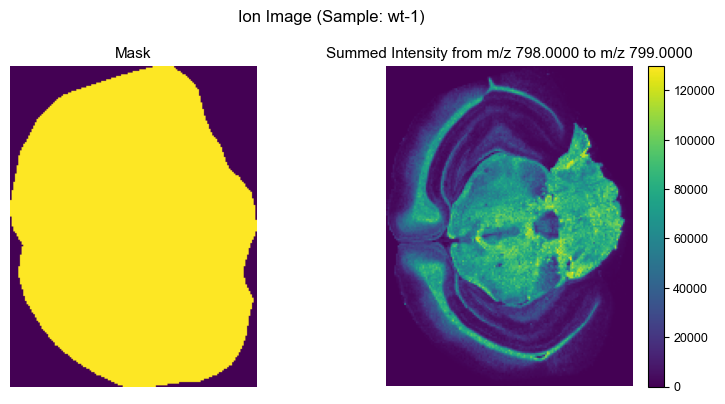

wt-1 (194, 149) (2509,) (2509, 194, 149)


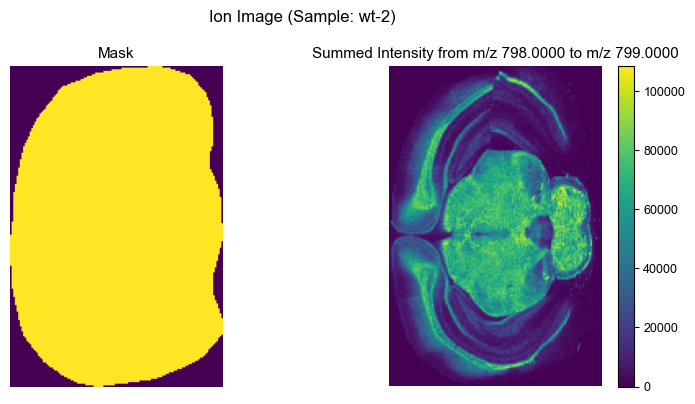

wt-2 (196, 130) (2076,) (2076, 196, 130)


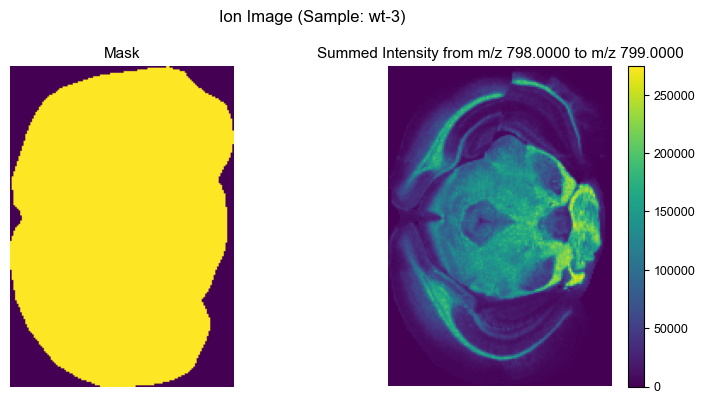

wt-3 (189, 132) (1757,) (1757, 189, 132)


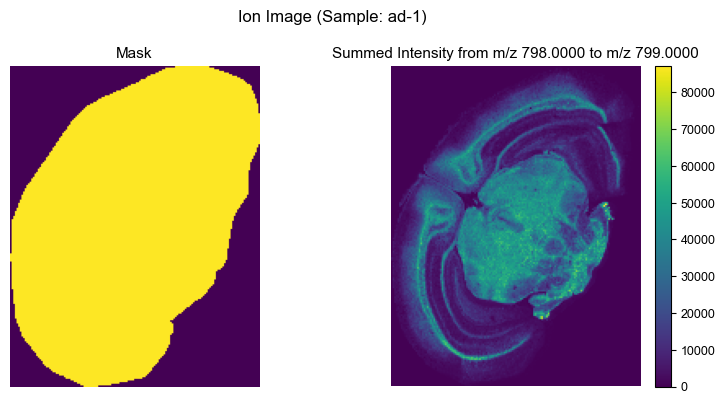

ad-1 (197, 153) (2559,) (2559, 197, 153)


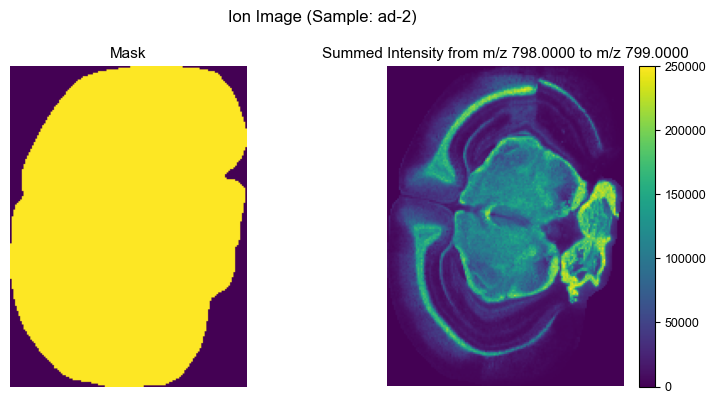

ad-2 (190, 140) (1783,) (1783, 190, 140)


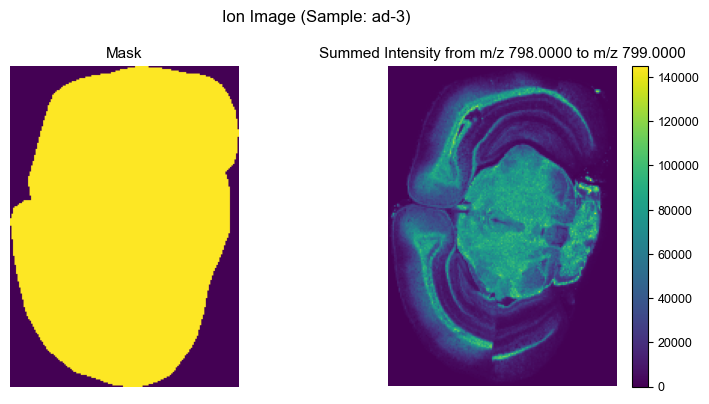

ad-3 (213, 152) (2277,) (2277, 213, 152)


In [6]:
for i in range(len(inputs)):
    display_ion_image_from_inputs(inputs[i], 798, 799)
    print(inputs[i][0], np.shape(inputs[i][1]), np.shape(inputs[i][2]), np.shape(inputs[i][3]))

The ion images need to be normalized and transformed to a same shape before input to the network. The `get_input_size` function generates the maximum width and height among the ion images in the input data.

In [7]:
inputs_after = input_normalization(inputs)
ih, iw = get_input_size(inputs_after)
print(ih, iw)
inputs_after = resize_images(inputs_after, ih, iw)

213 153


## 3. Model training with parameters optimization

Now the embedding model can be trained with the ion images. To get appropriate parameters of model training, Bayesian optimization is used. Below, the average intra-sample correlation between embeddings and ion images are used as optimization objective.

In [12]:
from bayes_opt import BayesianOptimization
import torch
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
from scipy.stats import spearmanr

In [13]:
def bayes_objective(
        train_pairs_per_sample,
        alpha_height_ratio,
        sigma_height_ratio,
        max_rotation_degree,
        batch_size,
        optimizer,
        embedding_dim,
        num_inception_blocks,
        dropout_p,
        lr):
    # ----------------------------
    # Convert types
    # ----------------------------
    class Args:
        seed = 42
        train_pairs_per_sample = 2000 # [2000, 3000, 4000, 5000] (0, 4)
        test_pairs_per_sample = 2000
        alpha_height_ratio = 2  # (0, 3)
        sigma_height_ratio = 0.12  # (0, 1)
        max_rotation_degree = 45  # (0, 60)
        batch_size = 200  # [100, 200, 300, 400, 500] (0, 5)
        optimizer = "Adam"  # ['Adam','SGD','RMSprop','Adagrad','AdamW'] (0, 5)
        lr = 1e-4  # [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
        max_epochs = 60
        early_stop_patience = 8
        early_stop_delta = 1e-4
        output_path = r"E:\yangjun\msi\MSI_IIE_article\scl_nc_gastric\parameter_tuning"
        model_data_file = 'mstest-tuning.pth'
    
        embedding_dim = 28  # (28, 256)
        num_inception_blocks = 4  # (1, 5)
        dropout_p = 0.2 # (0, 0.4)

    train_pairs_list = [1000, 2000, 3000, 4000]
    opt_list = ['Adam','SGD','RMSprop','Adagrad','AdamW']
    learn_list = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
    b_list = [100, 200, 300, 400, 500]
    args = Args()
    alpha_height_ratio = float(alpha_height_ratio)
    sigma_height_ratio = float(sigma_height_ratio)
    max_rotation_degree = int(round(max_rotation_degree))
    ib = int(np.clip(np.floor(batch_size), 0, len(b_list) - 1))
    batch_size = b_list[ib]
    idx = int(np.clip(np.floor(optimizer), 0, len(opt_list) - 1))
    optimizer = opt_list[idx]
    idy = int(np.clip(np.floor(lr), 0, len(learn_list) - 1))
    lr = learn_list[idy]
    idj = int(np.clip(np.floor(train_pairs_per_sample), 0, len(train_pairs_list) - 1))
    train_pairs_per_sample = train_pairs_list[idj]
    embedding_dim = int(round(embedding_dim))
    num_inception_blocks = int(round(num_inception_blocks))
    dropout_p = float(dropout_p)

    # ----------------------------
    # Update args
    # ----------------------------
    args.alpha_height_ratio = alpha_height_ratio
    args.sigma_height_ratio = sigma_height_ratio
    args.max_rotation_degree = max_rotation_degree
    args.batch_size = batch_size
    args.optimizer = optimizer
    args.embedding_dim = embedding_dim
    args.lr = lr
    args.train_pairs_per_sample = train_pairs_per_sample
    args.num_inception_blocks = num_inception_blocks
    args.dropout_p = dropout_p
    print(args.train_pairs_per_sample,
        args.alpha_height_ratio,
        args.sigma_height_ratio,
        args.max_rotation_degree,
        args.batch_size,
        args.optimizer,
        args.embedding_dim,
        args.num_inception_blocks,
        args.dropout_p,
        args.lr)
    # ----------------------------
    # Reproducibility
    # ----------------------------
    np.random.seed(args.seed)

    # ----------------------------
    # Build model
    # ----------------------------
    model = MultiscaleEmbedding_p(
        embedding_dim=args.embedding_dim,
        num_inception_blocks = args.num_inception_blocks,
        dropout_p = args.dropout_p
    )
    
    train_data, test_data = get_training_test_data(inputs_after, aug_per_sample=20,
                            alpha_height_ratio=args.alpha_height_ratio,
                             sigma_height_ratio=args.sigma_height_ratio,
                             max_rotation_degree=args.max_rotation_degree)
    train_loss_log, test_loss_log= train_embedding_pairs_test_pairs(train_data, test_data, model, args)

    final_test_loss = test_loss_log[-1]

    # Inference
    model.eval()
    outputs = []
    for s_input in inputs_after:
        sample_id, shape_mask, mz_array, intensity_array = s_input
        intensity_array[:, ~shape_mask] = 0
        n_images = len(intensity_array)
        all_embeddings = []
        for i in range(0, n_images, 200):
            batch_images = intensity_array[i: i + 200]
            batch_tensor = torch.FloatTensor(batch_images)
            batch_tensor = batch_tensor.to(device)
            batch_tensor = batch_tensor.unsqueeze(1)  # 在第1维度增加一个维度

            with torch.no_grad():
                embeddings = model(batch_tensor)
            all_embeddings.append(embeddings.cpu().numpy())
        all_embeddings = np.concatenate(all_embeddings, axis=0,
                                        dtype=np.float32)  # shape: (# ion images, embedding dimension)
        outputs.append([sample_id, mz_array, all_embeddings])

    # Correlation
    cr = 0
    mse = 0
    for i in range(len(inputs_after)):
        # Ion image similarity
        sample_id, shape_mask, _, intensity_array = inputs_after[i]
        num_images = len(intensity_array)
        # intensity_array[:, ~shape_mask] = 0
        X = intensity_array[:, shape_mask]
        X = X.astype(np.float64, copy=False)
        X -= X.mean(axis=1, keepdims=True)
        X /= X.std(axis=1, keepdims=True)
        img_corr = X @ X.T / (X.shape[1] - 1)   # Pearson similarity
        
        # Ion embedding similarity
        sample_id, _, ion_embedding = outputs[i]  # 范数为1的向量
        # ion_embedding -= ion_embedding.mean(axis=1, keepdims=True)  
        # ion_embedding /= ion_embedding.std(axis=1, keepdims=True)
        emb_corr = ion_embedding @ ion_embedding.T   # cosine similarity
        
        gt_vals = img_corr[np.triu_indices(num_images, k=1)]
        emb_vals = emb_corr[np.triu_indices(num_images, k=1)]
        ms = np.mean((gt_vals - emb_vals)** 2)
        # print("MSE: ", np.mean((gt_vals - emb_vals)** 2))
        spearman_corr, _ = spearmanr(gt_vals, emb_vals)
        cr += spearman_corr
        mse += ms
    print(f"MSE: {mse / len(inputs_after)}, correlation: {cr / len(inputs_after)}")

    # BO maximizes → negate loss
    return cr / len(inputs_after)

In [14]:
original_stdout = sys.stdout

In [15]:
import sys

sys.stdout = open(r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning\log_0331_bayesian.txt", "w")

pbounds = {
        "alpha_height_ratio": (0, 3),
        "sigma_height_ratio": (0, 1),
        "max_rotation_degree": (0, 60),
        "batch_size": (0, 5),
        "optimizer": (0, 5),
        "embedding_dim": (64, 256),
        "lr": (0, 6),
        "num_inception_blocks": (1, 5),
        "dropout_p": (0, 0.4),
        "train_pairs_per_sample": (0, 4)
    }

optimizer = BayesianOptimization(
    f=bayes_objective,
    pbounds=pbounds,
    random_state=42,
    verbose=2,
)

optimizer.maximize(
    init_points=5,  # random initialization
    n_iter=40,  # Bayesian steps
)

Training image augmentation in wt-3:  22%|█████████                                 | 305/1405 [01:30<03:43,  4.92it/s]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Training image augmentation in wt-1:  47%|███████████████████▌                      | 935/2007 [03:18<04:13,  4.24it/s]IOPub message rate exceeded.
The Jupyter server will temporarily stop sending output
to the client in order to avoid crashing it.
To change this limit, set the config variable
`--ServerApp.iopub_msg_rate_limit`.

Current values:
ServerApp.iopub_msg_rate_limit=1000.0 (msgs/sec)
ServerApp.rate_limit_window=3.0 (secs)

Epoch 28/60 [Train]: 100%|███████████████████████████████████████| 40/40 [00:34<00:00,  1.17it/s, Training loss=0.0318]


In [16]:
sys.stdout = original_stdout

In [17]:
best_params = optimizer.max
print(best_params)

{'target': np.float64(0.9761532285299547), 'params': {'alpha_height_ratio': np.float64(0.0), 'sigma_height_ratio': np.float64(1.0), 'max_rotation_degree': np.float64(38.334235566622986), 'batch_size': np.float64(0.0), 'optimizer': np.float64(0.0), 'embedding_dim': np.float64(121.8421768104899), 'lr': np.float64(0.0), 'num_inception_blocks': np.float64(5.0), 'dropout_p': np.float64(0.0), 'train_pairs_per_sample': np.float64(0.0)}}


## 4. Model training with optimized parameter

In [18]:
class Args:
    seed = 42
    train_pairs_per_sample = 2000 # [2000, 3000, 4000, 5000] (0, 4)
    test_pairs_per_sample = 2000
    alpha_height_ratio = 2  # (0, 3)
    sigma_height_ratio = 0.12  # (0, 1)
    max_rotation_degree = 45  # (0, 60)
    batch_size = 200  # [100, 200, 300, 400, 500] (0, 5)
    optimizer = "Adam"  # ['Adam','SGD','RMSprop','Adagrad','AdamW'] (0, 5)
    lr = 1e-4  # [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
    max_epochs = 60
    early_stop_patience = 8
    early_stop_delta = 1e-4
    output_path = r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning"
    model_data_file = 'mstest-tuning.pth'

    embedding_dim = 28  # (28, 256)
    num_inception_blocks = 4  # (1, 5)
    dropout_p = 0.2 # (0, 0.4)

alpha_height_ratio = np.float64(0.0)
sigma_height_ratio = np.float64(1.0)
max_rotation_degree = np.float64(38.334235566622986)
batch_size = np.float64(0)
optimizer = np.float64(0)
embedding_dim = np.float64(121.8421768104899)
lr = np.float64(0.0)
num_inception_blocks = np.float64(5.0)
dropout_p = np.float64(0.0)
train_pairs_per_sample = np.float64(0.0)


train_pairs_list = [1000, 2000, 3000, 4000]
opt_list = ['Adam','SGD','RMSprop','Adagrad','AdamW']
learn_list = [1e-3, 1e-4, 1e-5, 1e-6, 1e-7, 1e-8]
b_list = [100, 200, 300, 400, 500]
args = Args()
alpha_height_ratio = float(alpha_height_ratio)
sigma_height_ratio = float(sigma_height_ratio)
max_rotation_degree = int(round(max_rotation_degree))
ib = int(np.clip(np.floor(batch_size), 0, len(b_list) - 1))
batch_size = b_list[ib]
idx = int(np.clip(np.floor(optimizer), 0, len(opt_list) - 1))
optimizer = opt_list[idx]
idy = int(np.clip(np.floor(lr), 0, len(learn_list) - 1))
lr = learn_list[idy]
idj = int(np.clip(np.floor(train_pairs_per_sample), 0, len(train_pairs_list) - 1))
train_pairs_per_sample = train_pairs_list[idj]
embedding_dim = int(round(embedding_dim))
num_inception_blocks = int(round(num_inception_blocks))
dropout_p = float(dropout_p)

alpha_height_ratio, sigma_height_ratio, max_rotation_degree, batch_size, optimizer, lr, train_pairs_per_sample, embedding_dim, num_inception_blocks, dropout_p

(0.0, 1.0, 38, 100, 'Adam', 0.001, 1000, 122, 5, 0.0)

In [19]:
import sys

class Args:
    seed = 42
    train_pairs_per_sample = 1000
    test_pairs_per_sample = 2000
    alpha_height_ratio = 0
    sigma_height_ratio = 1
    max_rotation_degree = 38  # (0, 60)
    batch_size = 100
    optimizer = "Adam"  # ['Adam','SGD','RMSprop','Adagrad','AdamW']
    lr = 0.001
    max_epochs = 60
    early_stop_patience = 20
    early_stop_delta = 1e-4
    output_path = output_path = r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning"
    model_data_file = 'optimized_model_20260402.pth'

    embedding_dim = 122
    num_inception_blocks = 5
    dropout_p = 0

args = Args()
train_data, test_data = get_training_test_data(inputs_after, aug_per_sample=20,
                                                alpha_height_ratio=args.alpha_height_ratio,
                                                 sigma_height_ratio=args.sigma_height_ratio,
                                                 max_rotation_degree=args.max_rotation_degree,
                                              no_distortion=0.2)
model = MultiscaleEmbedding_p(
        embedding_dim=args.embedding_dim,
        num_inception_blocks = args.num_inception_blocks,
        dropout_p = args.dropout_p
    )
train_loss_log, test_loss_log = train_embedding_pairs_test_pairs(
        train_data, test_data, model, args)

Training image augmentation in ad-3: 100%|█████████████████████████████████████████| 1821/1821 [08:57<00:00,  3.39it/s]


Preparing test data.


Test image augmentation in ad-3: 100%|███████████████████████████████████████████████| 456/456 [02:58<00:00,  2.55it/s]


Complete train and test data preparation.


Epoch 1/60 [Train]: 100%|████████████████████████████████████████| 60/60 [00:17<00:00,  3.44it/s, Training loss=0.0227]


...

Epoch 58/60: Train Loss: 0.0075, Test Loss: 0.0070


Epoch 59/60 [Train]: 100%|██████████████████████████████████████| 60/60 [00:15<00:00,  3.92it/s, Training loss=0.00732]


Epoch 59/60: Train Loss: 0.0078, Test Loss: 0.0067


Epoch 60/60 [Train]: 100%|██████████████████████████████████████| 60/60 [00:21<00:00,  2.84it/s, Training loss=0.00593]


Epoch 60/60: Train Loss: 0.0077, Test Loss: 0.0068
Time of preparing data: 0.00017213821411132812. Time of training model: 1508.569790840149


## 5. Downstream analysis on the ion image embeddings

In [12]:
class Args:
    seed = 42
    train_pairs_per_sample = 1000
    test_pairs_per_sample = 2000
    alpha_height_ratio = 0
    sigma_height_ratio = 1
    max_rotation_degree = 38  # (0, 60)
    batch_size = 100
    optimizer = "Adam"  # ['Adam','SGD','RMSprop','Adagrad','AdamW']
    lr = 0.001
    max_epochs = 60
    early_stop_patience = 20
    early_stop_delta = 1e-4
    output_path = output_path = r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning"
    model_data_file = 'optimized_model_20260402.pth'

    embedding_dim = 122
    num_inception_blocks = 5
    dropout_p = 0

args = Args()

model = MultiscaleEmbedding_p(
        embedding_dim=args.embedding_dim,
        num_inception_blocks = args.num_inception_blocks,
        dropout_p = args.dropout_p
    )

After defining the model with the optimized parameters, we apply the model on all images of the dataset and get the output. `outputs` is a list of output embeddings of all the samples. Each element is a list of `[sample_id, mz_array, embedding_array]`.

In [9]:
outputs = ion_clustering.extract_embeddings(inputs_after, model,
                             r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning\optimized_model_20260402.pth',
                             batch_size=200)

The `multi_files_pca_kmeans` function can perform PCA and K-means clustering on the embeddings. The two result pictures are the score plots colored on samples or clusters.

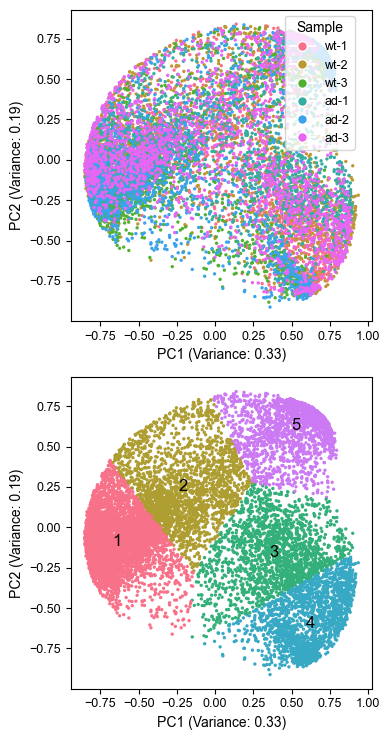

In [10]:
pca_results, sample_ids, mz_values, cluster_labels = ion_clustering.multi_files_pca_kmeans(outputs, n_clusters=5)

From the summed ion images of different clusters, each cluster has different spatial patterns.

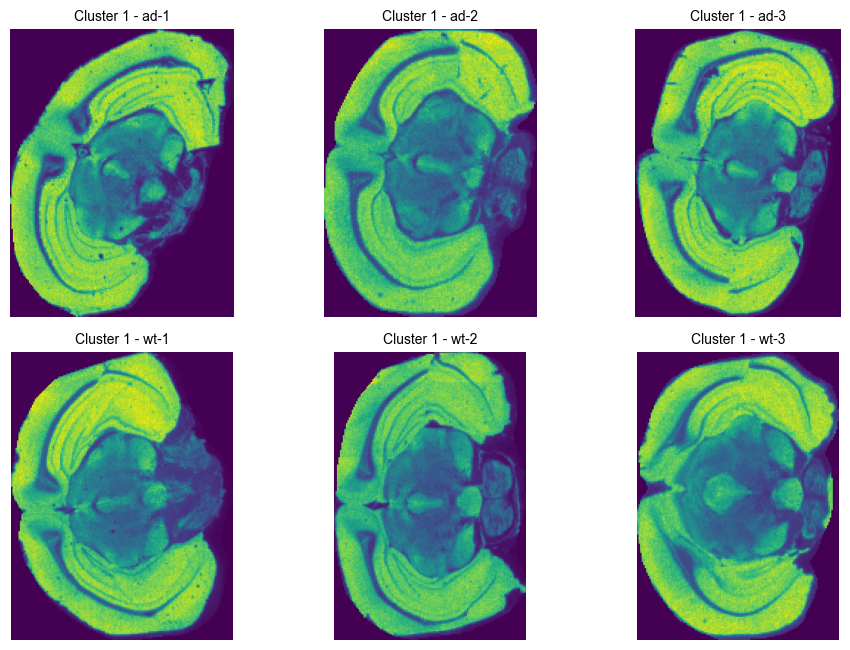

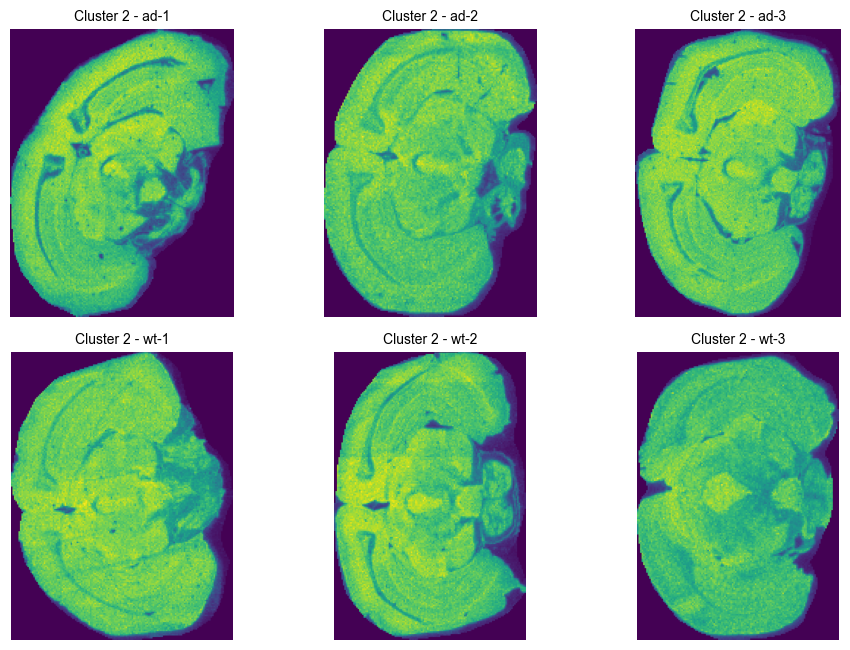

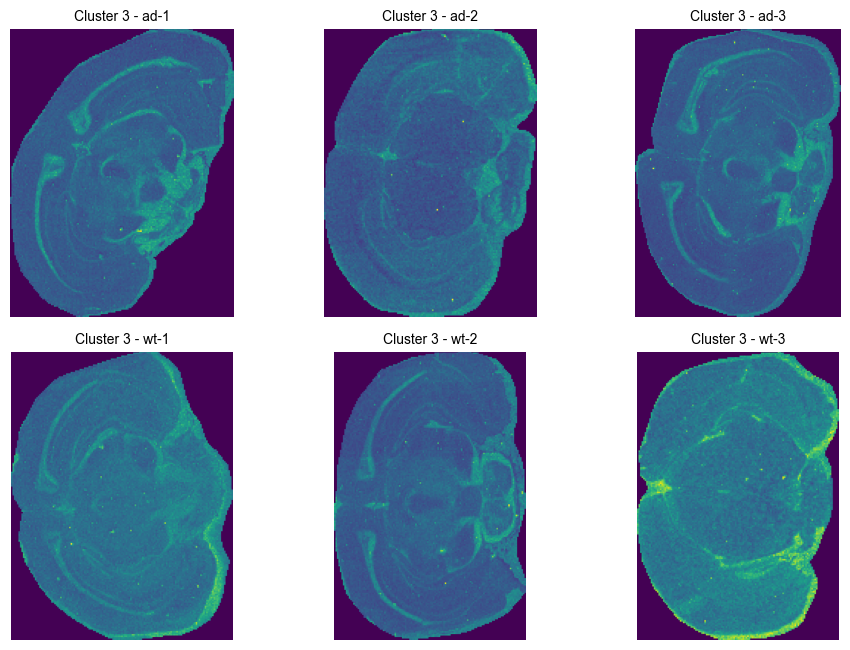

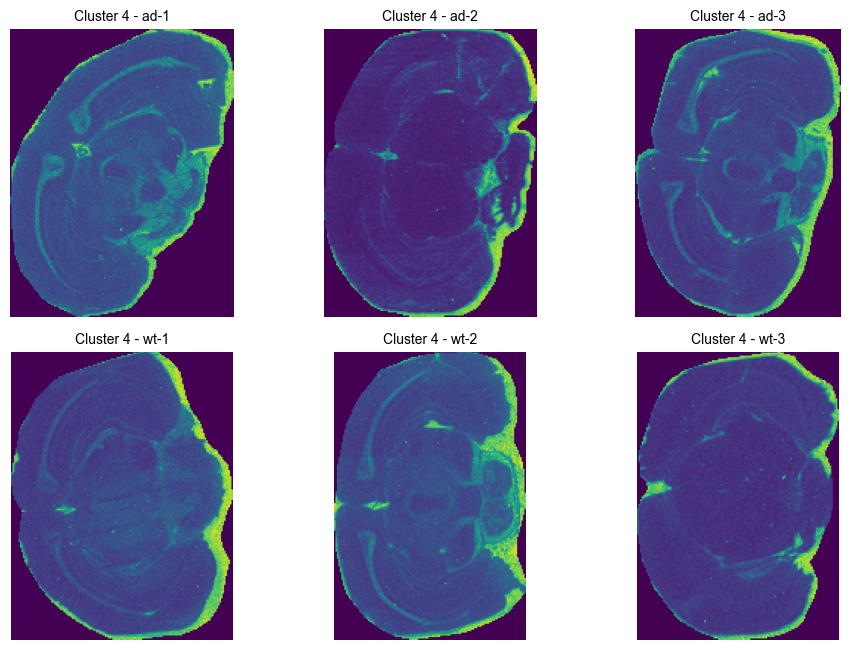

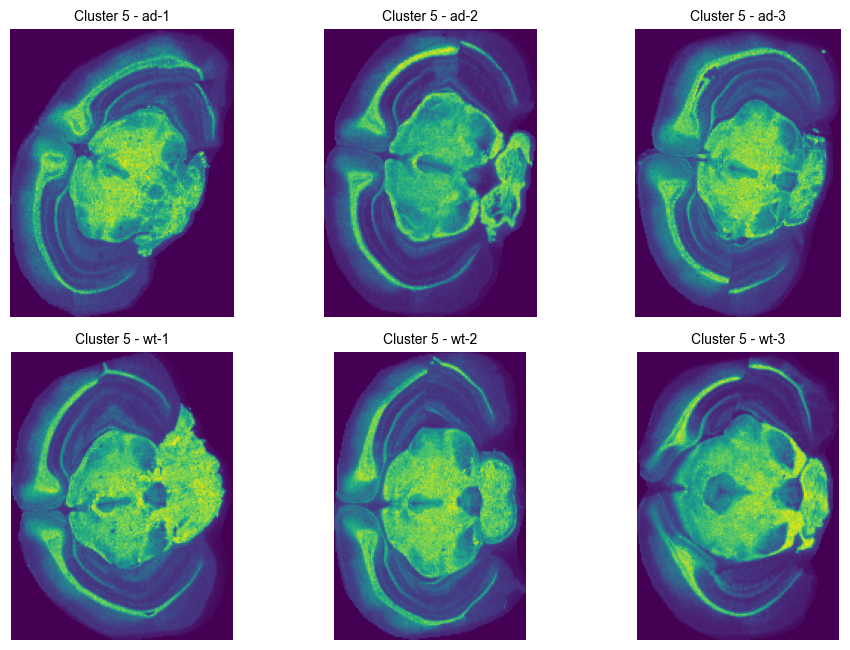

In [14]:
for i in range(1, 6):
    ion_clustering.single_cluster_visualization(inputs, sample_ids, cluster_labels, i)

## 6. Get ion images from only annotated molecules

In most cases, analysis on above embeddings are adequate. Here, as the amount of ion images is too great, we only focus on the annotated molecules.\
To improve the quality of the ion images, we extracted them from the raw data again.

In [6]:
import pandas as pd
mol_tab = pd.read_csv(r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\annotations_ms2_metaspace.csv")
mol_tab['label'] = mol_tab['moleculeNames'].str.split(', ').str[0]
mol_tab

,formula,adduct,ion,mz,moleculeNames,moleculeIds,label
0,C8H18N2O4S,M-H,C8H18N2O4S-H-,237.091452,15(R)-hydroperoxy-EPE,HMDB0062295,15(R)-hydroperoxy-EPE
1,C16H14O2,M-H,C16H14O2-H-,237.092103,"4'-Methoxychalcone, Cinnamyl benzoate, Benzyl ...","HMDB0032585, HMDB0029700, HMDB0040286",4'-Methoxychalcone
2,C10H7Cl2N3O,M-H,C10H7Cl2N3O-H-,253.989341,Anagrelide,HMDB0014406,Anagrelide
3,C16H32O2,M-H,C16H32O2-H-,255.232954,"Butyl dodecanoate, Dodecyl butyrate, Hexyl dec...","HMDB0032065, HMDB0032249, HMDB0032324, HMDB000...",Butyl dodecanoate
4,C14H12O5,M-H,C14H12O5-H-,259.061197,"2-Methoxystypandrone, Orientalone, Pratenol A,...","HMDB0033265, HMDB0039616, HMDB0040630, HMDB012...",2-Methoxystypandrone
...,...,...,...,...,...,...,...
237,C84H148N4O34,M-H,C84H148N4O34-H-,1755.990221,Ganglioside GD2 (d18:1/24:1(15Z)),HMDB0004929,Ganglioside GD2 (d18:1/24:1(15Z))
238,C85H152N4O34,M-H,C85H152N4O34-H-,1772.021522,Ganglioside GD2 (d18:1/25:0),HMDB0004934,Ganglioside GD2 (d18:1/25:0)
239,C86H152N4O34,M-H,C86H152N4O34-H-,1784.021522,Ganglioside GD2 (d18:1/26:1(15Z)),HMDB0004930,Ganglioside GD2 (d18:1/26:1(15Z))
240,C87H155N3O34,M-H,C87H155N3O34-H-,1785.041923,Ganglioside GD2 (d18:0/26:1(17Z)),HMDB0011851,Ganglioside GD2 (d18:0/26:1(17Z))


In [7]:
tar_list = mol_tab["mz"].tolist()

Similar to `get_samples_ion_images` above, here we use `get_samples_ion_images_only_tar` function to extract ion images with annotations.

In [44]:
sample_path_list = [
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal6_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal7_s2_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section4_jan25_animal8_wt_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section1_jan25_animal5_5xfad_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section4_jan25_animal9_s2_5xfad_neg.imzML',
        r'G:\msi_data\ad_mice_brain_sweedler\section7b2_jan25_animal10_s2_5xfad_neg.imzML'
    ]

sample_id_list = ['wt-1', 'wt-2', 'wt-3', 'ad-1', 'ad-2', 'ad-3']
output_dir = r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\ion_images_tar'
noise_threshold_list = [1e3, 1e3, 1e3, 1e3, 1e3, 1e3]

In [47]:
ion_images.get_samples_ion_images_only_tar(sample_path_list=sample_path_list,
                               sample_id_list=sample_id_list,
                               ppm_torelance=20,
                               output_directory=output_dir,
                                          target_mz_list=[tar_list, tar_list, tar_list, tar_list, tar_list, tar_list])

Exacting ion images from wt-1...


100%|████████████████████████████████████████████████████████████████████████████| 22358/22358 [08:30<00:00, 43.82it/s]


(194, 149) (242,) (242, 194, 149)
Exacting ion images from wt-2...


100%|████████████████████████████████████████████████████████████████████████████| 21178/21178 [06:38<00:00, 53.15it/s]


(197, 153) (242,) (242, 197, 153)
Exacting ion images from ad-2...


100%|████████████████████████████████████████████████████████████████████████████| 21522/21522 [05:59<00:00, 59.82it/s]


(190, 140) (242,) (242, 190, 140)
Exacting ion images from ad-3...


100%|████████████████████████████████████████████████████████████████████████████| 24947/24947 [07:20<00:00, 56.58it/s]


(213, 152) (242,) (242, 213, 152)


In [8]:
with open(r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\ion_images_tar\input_data.pkl', 'rb') as f:
        inputs = pickle.load(f)  # inputs: List of [sample_id, msi_mask, mz_array, intensity_array]

# All ion images detected from dataset
for i in range(len(inputs)):
    print(inputs[i][0], np.shape(inputs[i][1]), np.shape(inputs[i][2]), np.shape(inputs[i][3]))

wt-1 (194, 149) (242,) (242, 194, 149)
wt-2 (196, 130) (242,) (242, 196, 130)
wt-3 (189, 132) (242,) (242, 189, 132)
ad-1 (197, 153) (242,) (242, 197, 153)
ad-2 (190, 140) (242,) (242, 190, 140)
ad-3 (213, 152) (242,) (242, 213, 152)


In [9]:
inputs_after = input_normalization(inputs)
ih, iw = get_input_size(inputs_after)
print(ih, iw)
inputs_after = resize_images(inputs_after, ih, iw)

213 153


Apply `shape_mask` on the ion images to ensure the non-tissue regions are zero.

In [10]:
for s_input in inputs_after:
    sample_id, shape_mask, _, intensity_array = s_input
    intensity_array[:, ~shape_mask] = 0

In [13]:
import ion_clustering
outputs = ion_clustering.extract_embeddings(inputs_after, model,
                             r'E:\yangjun\msi\MSI_IIE_article\sweedler_ad\parameter_tuning\optimized_model_20260402.pth',
                             batch_size=200)

D:\Programs\Anaconda\envs\yj_msi\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=6.
  warnings.warn(


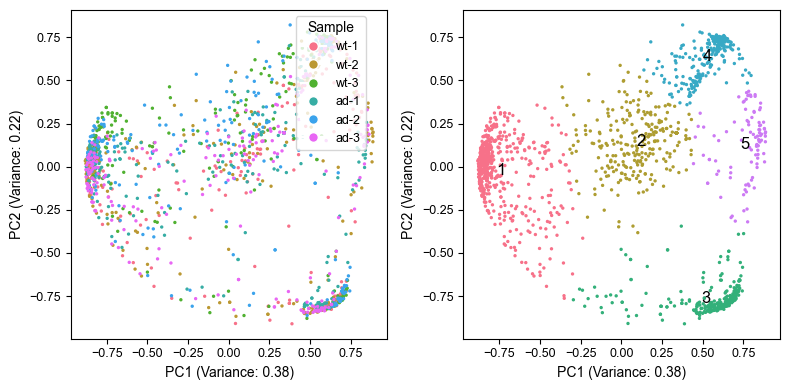

In [14]:
pca_results, sample_ids, mz_values, cluster_labels = ion_clustering.multi_files_pca_kmeans(outputs, n_clusters=5,
                                                                                          output_path=r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\clustering\pca_cluster_horizontal.png")

Rotate the ion images for better visualization.

In [15]:
# Right rotation on images in inputs and inputs_after
rotated_inputs = []

for s_input in inputs:
    sample_id, shape_mask, _, intensity_array = s_input  # (n, h, w)

    # Rotate each 2D slice 90° clockwise
    rotated_array = np.rot90(intensity_array, k=-1, axes=(1, 2))

    rotated_inputs.append((sample_id, shape_mask, _, rotated_array))

rotated_inputs_after = []

for s_input in inputs_after:
    sample_id, shape_mask, _, intensity_array = s_input  # (n, h, w)

    # Rotate each 2D slice 90° clockwise
    rotated_array = np.rot90(intensity_array, k=-1, axes=(1, 2))

    rotated_inputs_after.append((sample_id, shape_mask, _, rotated_array))

Accroding to the clustering results, the cluster 4 are basically matrix signal. So we remove the molecules with more than 2 images localized in cluster 4.

In [16]:
matrix_m = []
for _i, _m in enumerate(mz_values[:242]):
    s1_i, s2_i, s3_i, s4_i, s5_i, s6_i = (
        _i, _i + 242, _i + 242 * 2,
        _i + 242 * 3, _i + 242 * 4, _i + 242 * 5
    )
    
    clus = [
        cluster_labels[s1_i],
        cluster_labels[s2_i],
        cluster_labels[s3_i],
        cluster_labels[s4_i],
        cluster_labels[s5_i],
        cluster_labels[s6_i]
    ]
    
    if clus.count(4) >= 2:
        matrix_m.append((_i, _m))

In [17]:
matrix_m[:5]

[(0, np.float32(237.09143)),
 (1, np.float32(237.09143)),
 (4, np.float32(259.06128)),
 (5, np.float32(269.04526)),
 (6, np.float32(269.08163))]

In [18]:
remove_ids = [i for i, _ in matrix_m]
mask = np.ones(242, dtype=bool)
mask[remove_ids] = False

In [19]:
no_matrix_outputs = []
for i, output in enumerate(outputs):
    sample_id, mz_list, embeddings = output
    no_matrix_outputs.append([sample_id, mz_list[mask], embeddings[mask]])
    print(no_matrix_outputs[-1][0], no_matrix_outputs[-1][1].shape, no_matrix_outputs[-1][2].shape,)

wt-1 (172,) (172, 122)
wt-2 (172,) (172, 122)
wt-3 (172,) (172, 122)
ad-1 (172,) (172, 122)
ad-2 (172,) (172, 122)
ad-3 (172,) (172, 122)


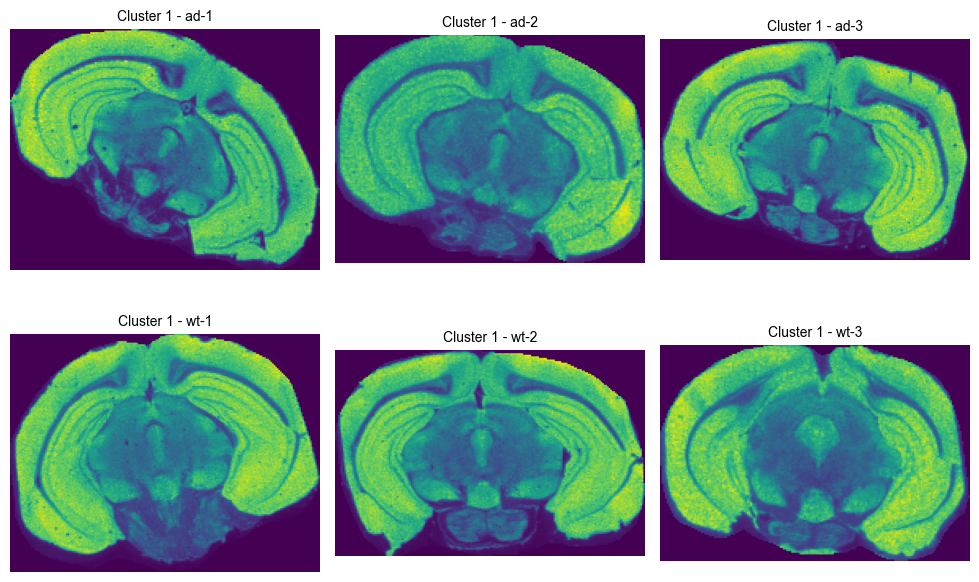

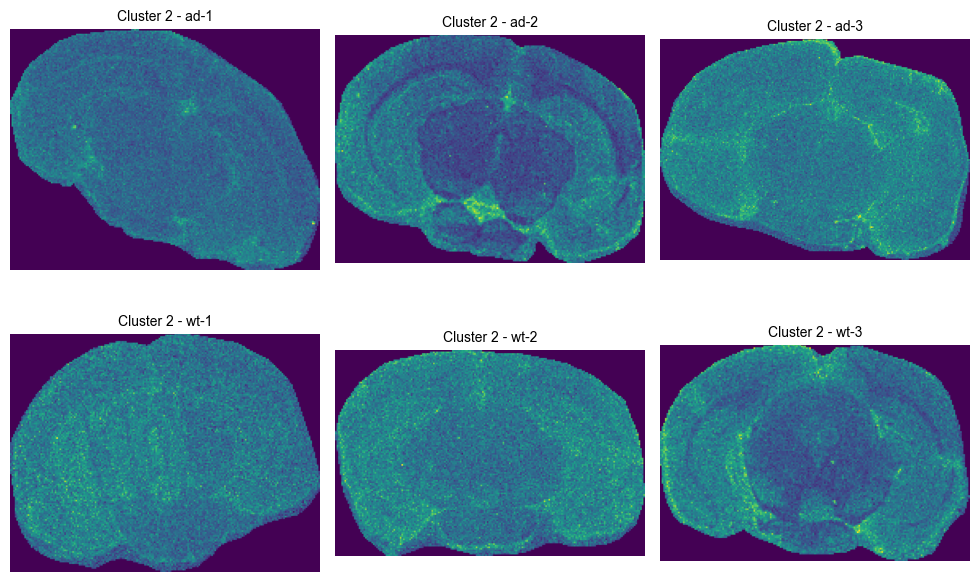

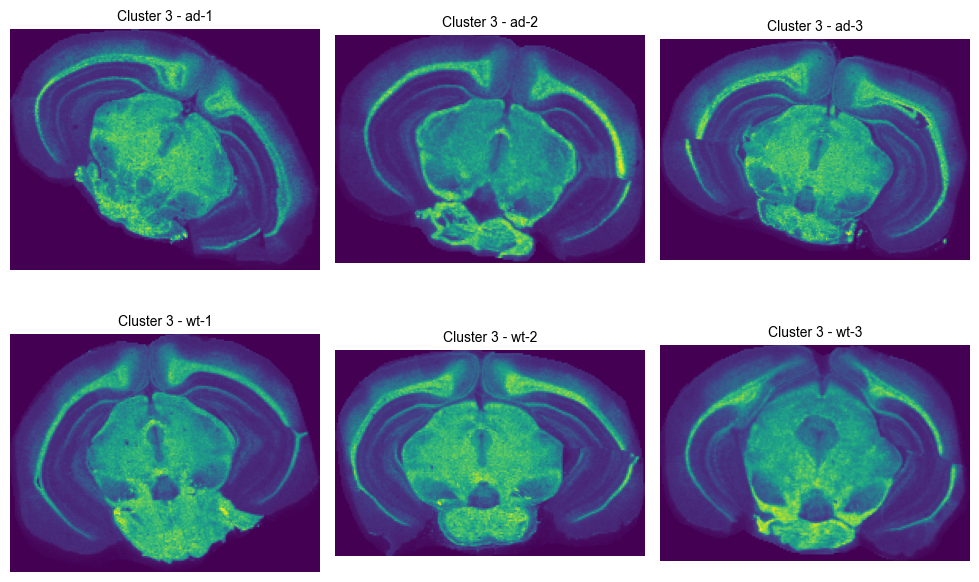

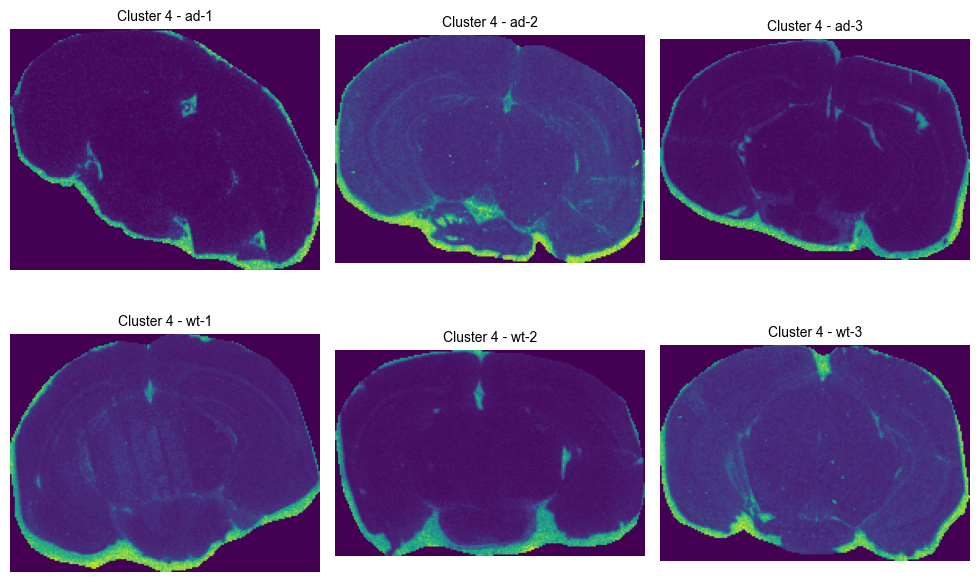

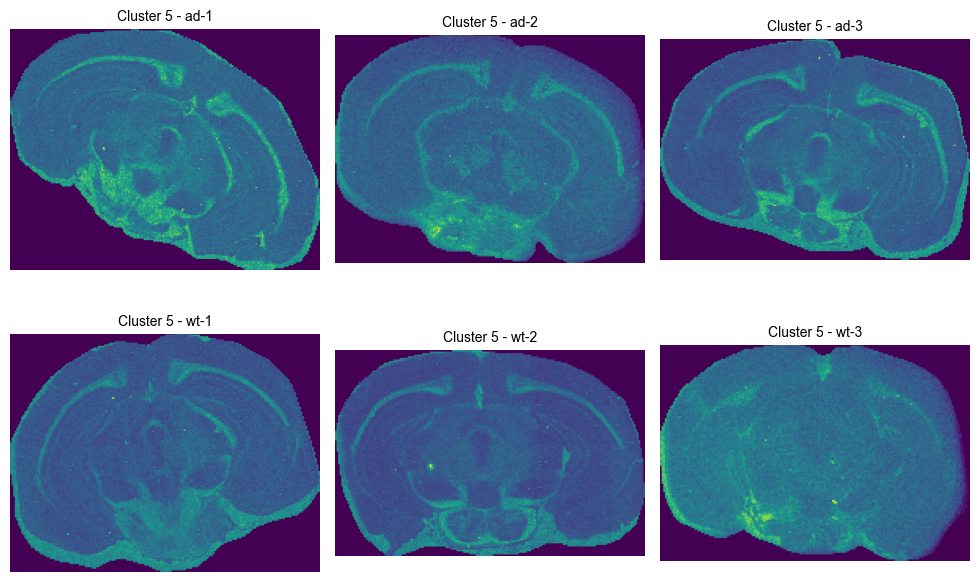

In [93]:
for i in range(1, 6):
    ion_clustering.single_cluster_visualization(rotated_inputs, sample_ids, cluster_labels, i,
                                               output_path=rf"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\clustering\cluster_{i}_summed_images_rotated.png")

## 7. Comparative analysis based on the ion image embeddings

With `two_classes_davies_bouldin` function, the davies bouldin distance can be computed on the two classes. The distance can reflect the difference of two classes.

In [20]:
m_sim = ion_clustering.two_classes_davies_bouldin(no_matrix_outputs, ['wt-1', 'wt-2', 'wt-3'], ['ad-1', 'ad-2', 'ad-3'], class1_name='wt', class2_name='ad')
sorted_m_sim = sorted(m_sim, key=lambda x: x[1])
sorted_m_sim[:5]

[(np.float32(1382.8154),
  np.float32(0.6852619),
  np.float32(0.23039365),
  np.float32(0.6724251)),
 (np.float32(480.30856),
  np.float32(0.8936761),
  np.float32(0.19776401),
  np.float32(0.44258544)),
 (np.float32(1179.7373),
  np.float32(1.0028936),
  np.float32(0.2507009),
  np.float32(0.49995512)),
 (np.float32(1410.8396),
  np.float32(1.0052481),
  np.float32(0.27049664),
  np.float32(0.5381689)),
 (np.float32(599.3207),
  np.float32(1.2978013),
  np.float32(0.16687301),
  np.float32(0.25716266))]

In [21]:
labeled_sorted_m_sim = []
for sms in sorted_m_sim:
    for index, row in mol_tab.iterrows():
        delta_mz = sms[0] * 10 / 1e6
        
        if row["mz"] - delta_mz < sms[0] < row["mz"] + delta_mz:
            sms_list = list(sms)
            sms_list.append(row["label"])
            sms = tuple(sms_list)
            labeled_sorted_m_sim.append(sms)
            break
labeled_sorted_m_sim[:5]

[(np.float32(1382.8154),
  np.float32(0.6852619),
  np.float32(0.23039365),
  np.float32(0.6724251),
  'GM2(36:1)'),
 (np.float32(480.30856),
  np.float32(0.8936761),
  np.float32(0.19776401),
  np.float32(0.44258544),
  'LPE(18:0)'),
 (np.float32(1179.7373),
  np.float32(1.0028936),
  np.float32(0.2507009),
  np.float32(0.49995512),
  'GM3(36:1)'),
 (np.float32(1410.8396),
  np.float32(1.0052481),
  np.float32(0.27049664),
  np.float32(0.5381689),
  'GM2(38:1)'),
 (np.float32(599.3207),
  np.float32(1.2978013),
  np.float32(0.16687301),
  np.float32(0.25716266),
  'LPI(18:0)')]

In [165]:
df = pd.DataFrame(labeled_sorted_m_sim, columns=["mz", "DBI", "Mean Within-Class Scatter", "Inter-Class Separation", "Annotation"])
df.to_csv(r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\comparative_DBI.csv", index=False)

For clearer labels, we manually removed the steroisomerism in the csv table.

In [22]:
df = pd.read_csv(r"E:\yangjun\msi\MSI_IIE_article\sweedler_ad\comparative_DBI_no_stero.csv")

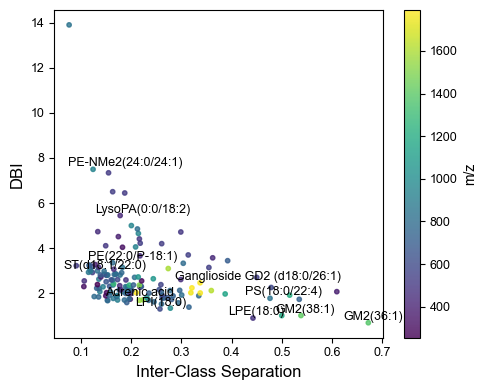

In [23]:
import matplotlib.pyplot as plt

# Plotting the data
plt.figure(figsize=(5, 4))
plt.scatter(df['Inter-Class Separation'], df['DBI'], c=df['mz'], cmap='viridis', s=10, alpha=0.8)

annotations = [0, 1, 3, 4, 20, 23, 82, 108, 124, 141, 145]
for i in annotations:
    plt.text(df['Inter-Class Separation'].iloc[i] - 0.05, df['DBI'].iloc[i], df['Annotation'].iloc[i],
             fontsize=9, ha='left', va='bottom', color='black')

# Labels and title
plt.xlabel('Inter-Class Separation', fontsize=12)
plt.ylabel('DBI', fontsize=12)
plt.colorbar(label='m/z')  # Colorbar for m/z values

# Display the plot
plt.tight_layout()
plt.show()

In [25]:
import re
def sanitize_filename(name):
    # Replace invalid characters with an underscore
    return re.sub(r'[\\/*?:"<>| ]', '_', name)

Below the top ranked differential compounds are displayed with their images in different samples.

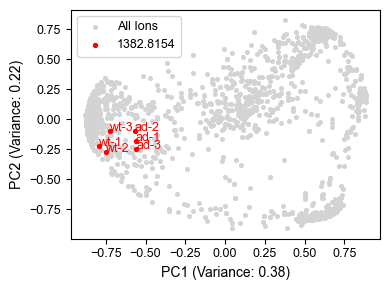

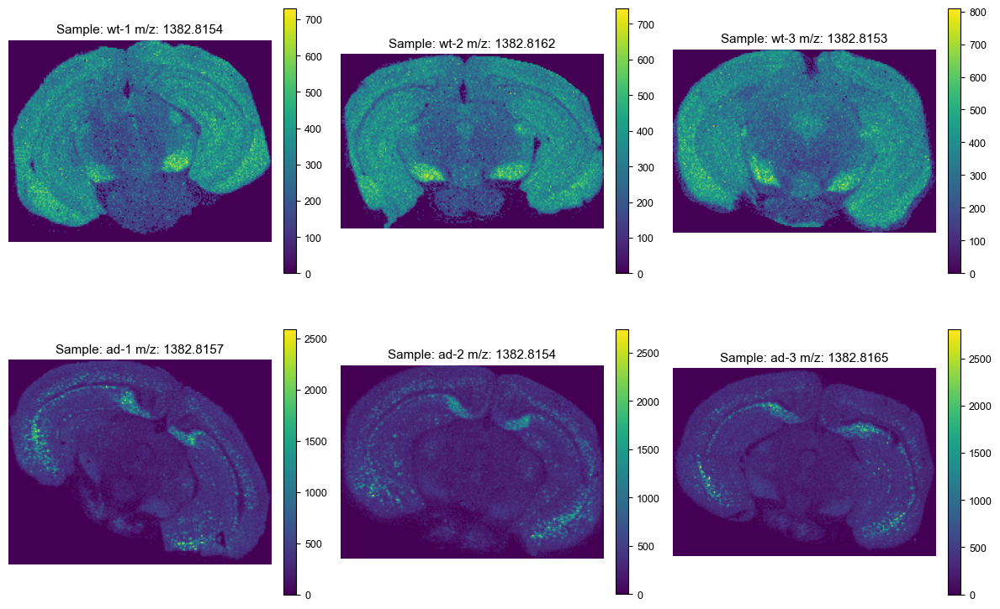

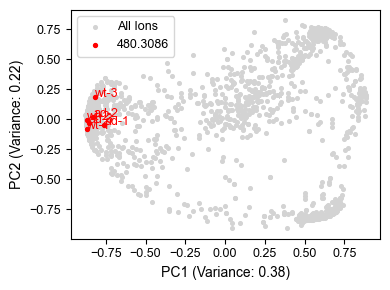

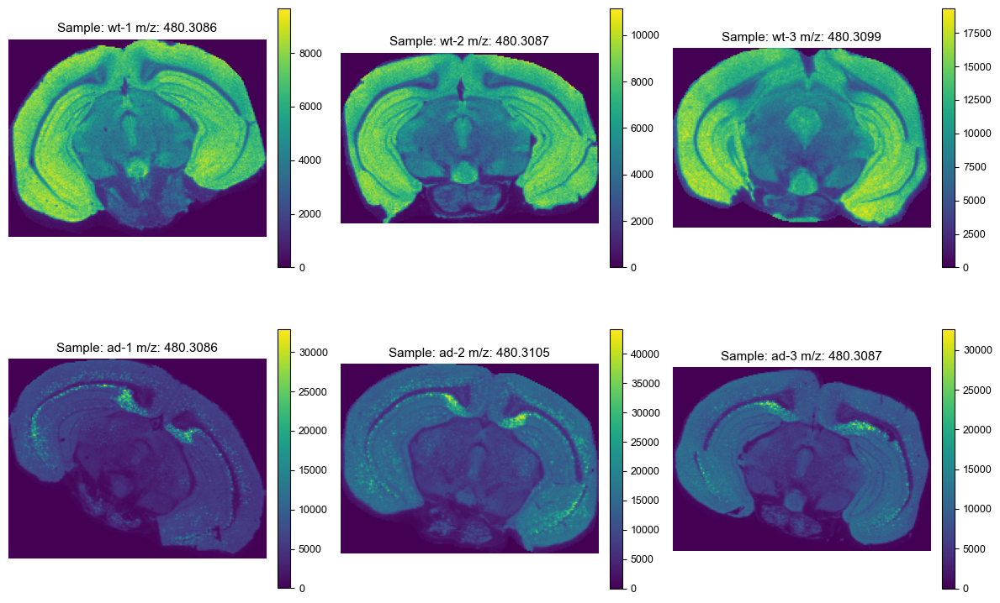

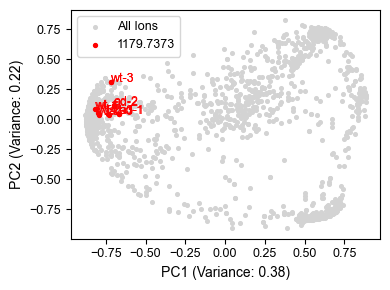

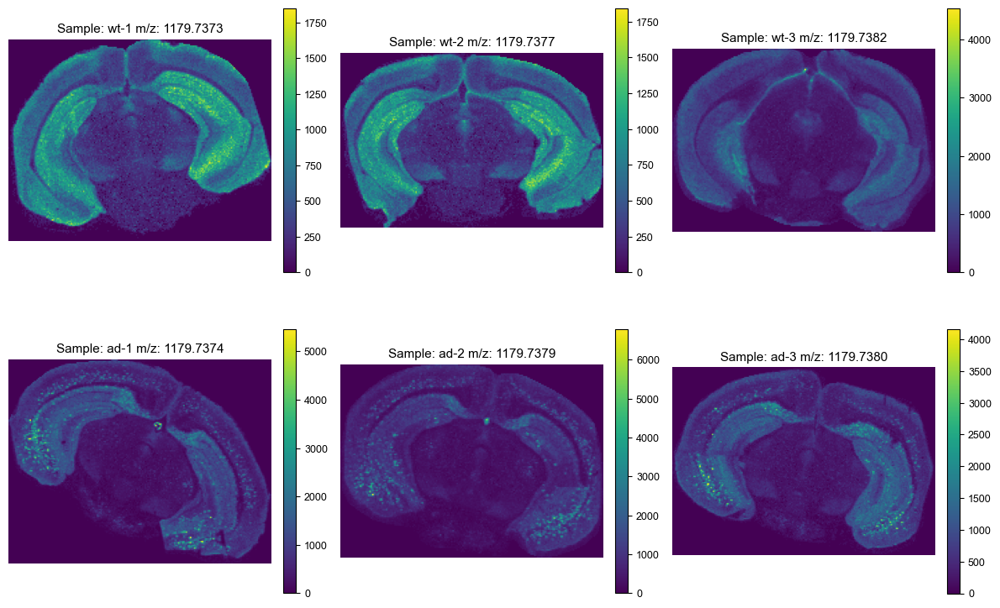

In [26]:
for i, msm in enumerate(labeled_sorted_m_sim[:3]):
    label_name = sanitize_filename(msm[4])
    ion_clustering.visualize_mz_embedding(outputs, ['wt-1', 'wt-2', 'wt-3', 'ad-1', 'ad-2', 'ad-3'],msm[0])
    ion_clustering.single_mz_visualization(rotated_inputs,  ['wt-1', 'wt-2', 'wt-3', 'ad-1', 'ad-2', 'ad-3'],msm[0], ppm=10)